# Churn Analysis and Customer Intelligence
### by Apoorava Modi
---

## 1. Import Database

In [2]:
# imported libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3


In [3]:
# Data Import: db file to pandas, storing each table to a separate df

#creating a path to access database file
from pathlib import Path
data_path = Path("data") / 'customer_churn_details.db'

# Connect to SQLite database

# Note: Keep python notebook and database file in the same folder to easily access and connect
conn = sqlite3.connect(data_path)


# sql query to Get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type='table';
"""

# read sql query in pandas
tables = pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn) # Read table into dataframe
    globals()[f"df_{table_name}"] = df                    # Create dynamic dataframe name
    print(f"Created dataframe: df_{table_name}")



Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [4]:
# Table names and column names

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    columns_query = f'PRAGMA table_info({table_name})'
    columns = pd.read_sql(columns_query, conn)
    print('columns:')
    print(columns['name'].tolist())


# Close connection
conn.close()


Table Name: db_customer
columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [5]:
# Duplicates entry check

for name in [ 'df_db_customer', 'df_db_subscription','df_db_support']:
    d = globals()[name]
    print(name, len(d), d['customerid'].nunique(), d['customerid'].duplicated().sum())

df_db_customer 12000 12000 0
df_db_subscription 12000 12000 0
df_db_support 7978 4798 3180


## 2. Data Cleaning

In [6]:
# a. rename column - name to customer_name

df_db_customer.rename(columns = {'name' : "customer_name"},inplace = True)


In [7]:
# b. Drop columns - interest and pincode

# using column names
df_db_customer.drop(columns = ["pincode","interests"],inplace= True)


In [8]:
# c. change data type - DOB

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

df_db_customer.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     12000 non-null  object        
 1   customer_name  12000 non-null  object        
 2   country        11551 non-null  object        
 3   state          12000 non-null  object        
 4   gender         12000 non-null  object        
 5   dob            12000 non-null  datetime64[ns]
dtypes: datetime64[ns](1), object(5)
memory usage: 562.6+ KB


In [9]:
# d. Data standardisation - gender

print("Unique gender values before:",df_db_customer['gender'].unique())

df_db_customer['gender'] = df_db_customer['gender'].replace({"Men" : "Male","Women" : "Female"})

print("Fixed gender values:",df_db_customer['gender'].unique())


Unique gender values before: ['Male' 'Female' 'Women' 'Men']
Fixed gender values: ['Male' 'Female']


In [10]:
# e. Missing values country

state_country = df_db_customer.dropna(subset= ["country"]).set_index("state")["country"].to_dict()

df_db_customer['country']= df_db_customer['country'].\
                                fillna(df_db_customer['state'].map(state_country))  

df_db_customer[df_db_customer['country'].isna()]


,customerid,customer_name,country,state,gender,dob


In [11]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               12000 non-null  object 
 1   subscription_start_date  12000 non-null  object 
 2   subscription_type        12000 non-null  object 
 3   renewal_date             12000 non-null  object 
 4   plan_type                12000 non-null  object 
 5   contract_type            12000 non-null  object 
 6   cancellation_date        3235 non-null   object 
 7   cancellation_reason      3235 non-null   object 
 8   monthly_charges          12000 non-null  float64
 9   cltv                     12000 non-null  int64  
 10  churn_score              12000 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 1.0+ MB


In [12]:
# f. fixing data type - subscription_start_date, cancellation_date

date_cols = ['subscription_start_date','cancellation_date','renewal_date' ] 
df_db_subscription[date_cols] = df_db_subscription[date_cols].apply(pd.to_datetime)

df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               12000 non-null  object        
 1   subscription_start_date  12000 non-null  datetime64[ns]
 2   subscription_type        12000 non-null  object        
 3   renewal_date             12000 non-null  datetime64[ns]
 4   plan_type                12000 non-null  object        
 5   contract_type            12000 non-null  object        
 6   cancellation_date        3235 non-null   datetime64[ns]
 7   cancellation_reason      3235 non-null   object        
 8   monthly_charges          12000 non-null  float64       
 9   cltv                     12000 non-null  int64         
 10  churn_score              12000 non-null  int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 1.0+ MB


In [13]:
# g. fixing data type - complaint_date

df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7978 entries, 0 to 7977
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      7978 non-null   object        
 1   complaint_date  7978 non-null   datetime64[ns]
 2   escalations     7978 non-null   object        
 3   csat_score      7978 non-null   int64         
 4   col_1           0 non-null      object        
 5   comment         5755 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(4)
memory usage: 374.1+ KB


In [14]:
# h. drop columns 'col_1','comment'

df_db_support= df_db_support.drop(columns= ['col_1','comment' ])
df_db_support.head()

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30


## 3. Feature Engineering and Data Analysis

### Feature Engineering

In [15]:
# Create support logs per customer 

support_summary = df_db_support.groupby('customerid').agg(
    complaints_count = ('customerid','size'),
    avg_csat_score = ('csat_score','mean'),
    escalations_count= ('escalations',lambda x: (x=='Y').sum()),
    escalations = ('escalations', lambda x: 1 if (x=='Y').any() else 0 ),
    last_complaint_date = ('complaint_date','max')
    ).reset_index().round({'avg_csat_score':2})


support_summary['customerid'].nunique(),df_db_support['customerid'].size

(4798, 7978)

In [16]:
support_summary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4798 entries, 0 to 4797
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customerid           4798 non-null   object        
 1   complaints_count     4798 non-null   int64         
 2   avg_csat_score       4798 non-null   float64       
 3   escalations_count    4798 non-null   int64         
 4   escalations          4798 non-null   int64         
 5   last_complaint_date  4798 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 225.0+ KB


In [17]:
# Added feature Churn flag

df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(),1,0)

df_db_subscription.head(50)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1
5,0013-MHZWF,2022-06-18,Paid,2025-06-18,Standard,Annual,NaT,None,17.99,720,22,0
6,0013-SMEOE,2021-09-30,Refferal,2024-09-30,Basic,Monthly,2024-11-15,Not enough content,8.99,230,79,1
7,0014-BMAQU,2020-02-14,Organic,2025-02-14,Premium,Annual,NaT,None,22.99,1840,5,0
8,0015-UOCOJ,2023-07-22,Organic,2024-07-22,Standard,Monthly,NaT,None,13.99,240,34,0
9,0016-QLJIS,2022-04-03,Organic,2025-04-03,Basic,Annual,NaT,None,6.99,335,41,0


In [18]:
# Final merged DataFrame

df = df_db_subscription.merge(df_db_customer, on = 'customerid', how = 'left')\
.merge(support_summary, on = 'customerid', how = 'left')
df

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaints_count,avg_csat_score,escalations_count,escalations,last_complaint_date
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaN,NaN,NaN,NaN,NaT
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2.0,35.00,1.0,1.0,2024-08-28
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,lalita,India,Delhi,Female,1978-02-15,NaN,NaN,NaN,NaN,NaT
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,mohan,India,Nagaland,Male,2001-08-30,NaN,NaN,NaN,NaN,NaT
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,mira,India,Delhi,Female,1990-05-05,1.0,20.00,1.0,1.0,2024-01-20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,9999-AIGRF,2020-04-26,Refferal,2025-04-26,Basic,Monthly,NaT,None,8.99,766,...,Kiran,India,Delhi,Male,1988-12-16,3.0,70.00,0.0,0.0,2024-04-04
11996,9999-HRIQA,2021-10-20,Refferal,2025-10-20,Premium,Monthly,NaT,None,22.99,1598,...,varun,India,Tamil Nadu,Male,1990-04-13,NaN,NaN,NaN,NaN,NaT
11997,9999-QURZV,2019-09-15,Paid,2025-09-15,Premium,Annual,NaT,None,16.99,1559,...,Mira,India,Madhya Pradesh,Female,1988-01-06,4.0,61.25,0.0,0.0,2023-07-19
11998,9999-SRBCU,2022-02-20,Refferal,2024-02-20,Premium,Annual,2024-02-22,Too expensive,20.99,411,...,varun,India,Karnataka,Male,1998-03-30,4.0,38.75,2.0,1.0,2024-02-21


In [19]:
# Handle zero-complaint accounts 

df['complaints_count']  = df['complaints_count'].fillna(0).astype('int')

In [20]:
# converted counts columns to int as it can not be floats

cols = ['escalations_count','escalations']
for i in cols:
    df[i]  = df[i].astype('Int64')
    print(f'{i} done')
df.info()

escalations_count done
escalations done
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               12000 non-null  object        
 1   subscription_start_date  12000 non-null  datetime64[ns]
 2   subscription_type        12000 non-null  object        
 3   renewal_date             12000 non-null  datetime64[ns]
 4   plan_type                12000 non-null  object        
 5   contract_type            12000 non-null  object        
 6   cancellation_date        3235 non-null   datetime64[ns]
 7   cancellation_reason      3235 non-null   object        
 8   monthly_charges          12000 non-null  float64       
 9   cltv                     12000 non-null  int64         
 10  churn_score              12000 non-null  int64         
 11  churn_flag               12000 non-null  int64       

In [21]:
# df.info()
df['escalations_count'].unique(),df['escalations'].unique(),df['complaints_count'].unique()

(<IntegerArray>
 [<NA>, 1, 0, 3, 2, 4, 6]
 Length: 7, dtype: Int64,
 <IntegerArray>
 [<NA>, 1, 0]
 Length: 3, dtype: Int64,
 array([ 0,  2,  1,  5,  3,  7,  6,  8,  4, 10, 11, 13,  9, 24, 12, 19]))

In [22]:
# Export cleaned dataset to current project root

df.to_csv("Customer_Churn_Analysis.csv")

print(f"Cleaned dataset successfully saved as 'Customer_Churn_Analysis_Cleaned.csv'")

Cleaned dataset successfully saved as 'Customer_Churn_Analysis_Cleaned.csv'


### Data Analysis

In [23]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaints_count', 'avg_csat_score', 'escalations_count',
       'escalations', 'last_complaint_date'],
      dtype='object')

In [24]:
# 1. Churn rate

churn_rate = df['churn_flag'].mean()*100

print("churn_rate :", round(churn_rate,2),"%")

churn_rate : 26.96 %


In [25]:
# 2. Retention Rate

retention_rate = round(100- churn_rate,2)

print('retention_rate :', retention_rate,"%")

retention_rate : 73.04 %


In [26]:
# 3.1 Churn rate (plan_type wise)

planwise_churn = df.groupby("plan_type")["churn_flag"].mean().mul(100).round(2).reset_index(name='Churn_rate_pct(%)')

planwise_churn.sort_values("Churn_rate_pct(%)",ascending=False)

,plan_type,Churn_rate_pct(%)
0,Basic,36.46
2,Standard,25.30
1,Premium,18.09


In [27]:
# 3.2 Planwise cost distribution

df.groupby("plan_type").agg(avg_monthly_cost = ('monthly_charges', 'mean')).round(2)

,avg_monthly_cost
plan_type,
Basic,8.31
Premium,21.04
Standard,12.93


In [28]:
# 4. Churn by State

state_churn = df.groupby("state")["churn_flag"].agg(
    User_count="count",
    churn_rate="mean"
).reset_index()
state_churn['churn_rate'] = (state_churn['churn_rate'] * 100).round(2)

print("top 10 states with more than 100 churned user are :\n")
print(state_churn[state_churn['User_count'] >= 100].nlargest(10, 'churn_rate'))


top 10 states with more than 100 churned user are :

             state  User_count  churn_rate
19  Madhya Pradesh         396       30.56
1            Assam         213       30.05
9          Gujarat         608       28.95
20     Maharashtra        1395       28.60
5     Chhattisgarh         158       28.48
10         Haryana         369       28.18
29   Uttar Pradesh        1134       28.13
26       Rajasthan         499       27.66
3            Bihar         306       27.12
24          Odisha         238       26.89


In [29]:
# 5. ARPU - Avg Revenue per user

arpu = df["monthly_charges"].mean()
print(f"ARPU = {arpu.round(2)} Rs")

ARPU = 13.57 Rs


In [30]:
# 6. Avg customer Tenure

date_max = max( df['cancellation_date'].max(),df['subscription_start_date'].max(),df['renewal_date'].max())

df['tenure_days'] = np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days , (date_max - df['subscription_start_date']).dt.days)
print("Avg Tenure (Days) =",int(df['tenure_days'].mean()),"days")

Avg Tenure (Days) = 1019 days


In [31]:
# 7. Revenue lost from churn users


revenue_at_risk = df[df["churn_flag"]==1]["monthly_charges"].sum()

print('Revenue at risk =',revenue_at_risk.round(2),"Rs")

Revenue at risk = 40172.65 Rs


In [32]:
# 8. Escalation Rate

escalation_rate = (df['escalations']==1).mean()*100

print("Escalation rate =",escalation_rate.round(2),'%')

Escalation rate = 29.95 %


In [33]:
# 9. Avg complaint rate

avg_complaints = df[df['last_complaint_date'].notna()]['customerid'].nunique()/df['customerid'].nunique()
print("Avg complaints per user =",round(avg_complaints,2))

Avg complaints per user = 0.4


In [34]:
# 10. Correlation Escalation vs churn

correlation  = df['escalations'].corr(df['churn_flag'])

print('correlation between escalations and churn_flag is', round(correlation,2))

correlation between escalations and churn_flag is 0.06


In [35]:
# 11. churn risk - create a column using existing col

conditions  = [
    (df['churn_score'] < 50),
    (df['churn_score'] >=50) & (df['churn_score']<70),
    df['churn_score'] >=70
]
level = ["low","med",'high'] 
df['churn_risk'] = np.select(conditions, level, default = "unknown")

In [36]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,state,gender,dob,complaints_count,avg_csat_score,escalations_count,escalations,last_complaint_date,tenure_days,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,None,13.99,627,...,Maharashtra,Male,1982-04-12,0,NaN,<NA>,<NA>,NaT,1752.0,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,Karnataka,Male,1995-11-23,2,35.0,1,1,2024-08-28,1501.0,high
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,None,6.99,210,...,Delhi,Female,1978-02-15,0,NaN,<NA>,<NA>,NaT,1137.0,low
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,None,22.99,1725,...,Nagaland,Male,2001-08-30,0,NaN,<NA>,<NA>,NaT,2427.0,low
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,Delhi,Female,1990-05-05,1,20.0,1,1,2024-01-20,419.0,high


## 4. Visualizations

In [37]:
df_visual = df.copy()
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaints_count', 'avg_csat_score', 'escalations_count',
       'escalations', 'last_complaint_date', 'tenure_days', 'churn_risk'],
      dtype='object')

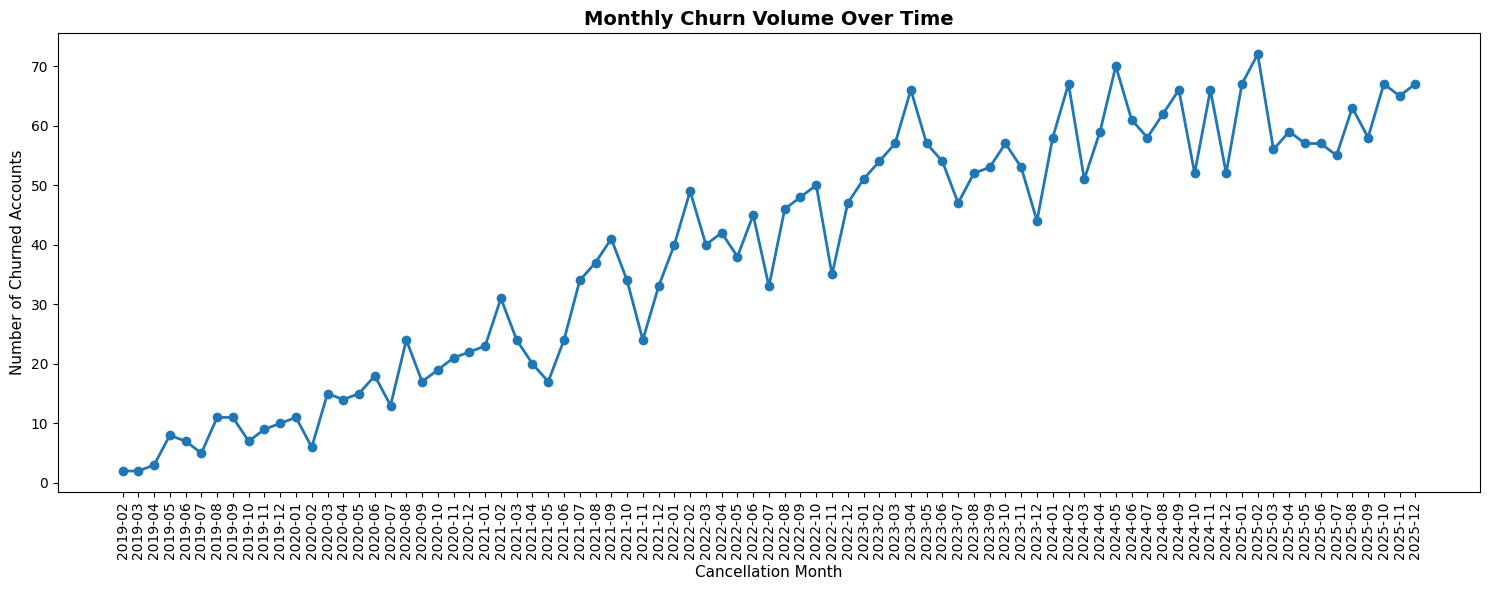

In [102]:
# 4.1 Chronological Monthly Churn Volume Trend
churn_trend_data = df[df['churn_flag'] == 1].copy()
churn_trend_data['cancellation_month'] = churn_trend_data['cancellation_date'].dt.to_period("M")
monthly_churn = churn_trend_data.groupby('cancellation_month').size().sort_index()

plt.figure(figsize=(15, 6))
plt.plot(
    monthly_churn.index.astype(str),
    monthly_churn.values,
    color='#1f77b4',
    marker='o',
    linewidth=2,
    markersize=6
)
plt.title("Monthly Churn Volume Over Time", fontsize=14, fontweight='bold')
plt.xlabel("Cancellation Month", fontsize=11)
plt.ylabel("Number of Churned Accounts", fontsize=11)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()



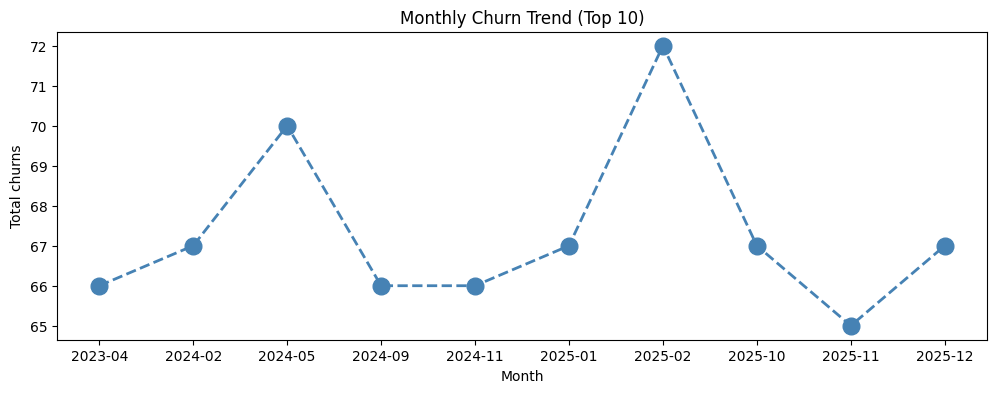

In [73]:
# 4.2 Monthly Churn Trend (Time series KPI)

df_visual['cancellation_month'] = df_visual['cancellation_date'].dt.to_period("M")

plt.figure(figsize=(12, 4))

churn_trend = df_visual[df['churn_flag']==1].groupby(df_visual['cancellation_month']).size().nlargest(10).sort_index()

plt.plot(churn_trend.index.astype('str'),churn_trend.values,color='steelblue', marker='o', linestyle='dashed',
         linewidth=2, markersize=12)

plt.title("Monthly Churn Trend (Top 10)")
plt.xlabel("Month")
plt.ylabel("Total churns")
plt.show()

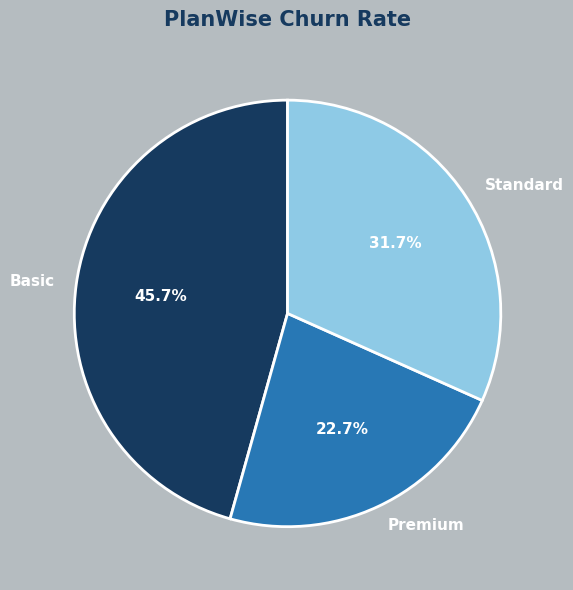

In [100]:
# 4.3 Churn by Plan Type

plan_trend = df.groupby('plan_type')['churn_flag'].mean()

plt.figure(figsize=(6, 6),facecolor= "#A9B1B6D9")

plt.pie(
    plan_trend.values,
    labels=plan_trend.index,
    autopct='%1.1f%%',
    colors=['#163A5F', '#2878B5', '#8ECAE6'],
    startangle=90,
    textprops={'fontsize': 11, 'color': 'white','fontweight' :'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2},

)


plt.title(
    'PlanWise Churn Rate',
    fontsize=15,
    color='#163A5F',
    fontweight='bold',
    pad=15
)
plt.tight_layout()
plt.show()

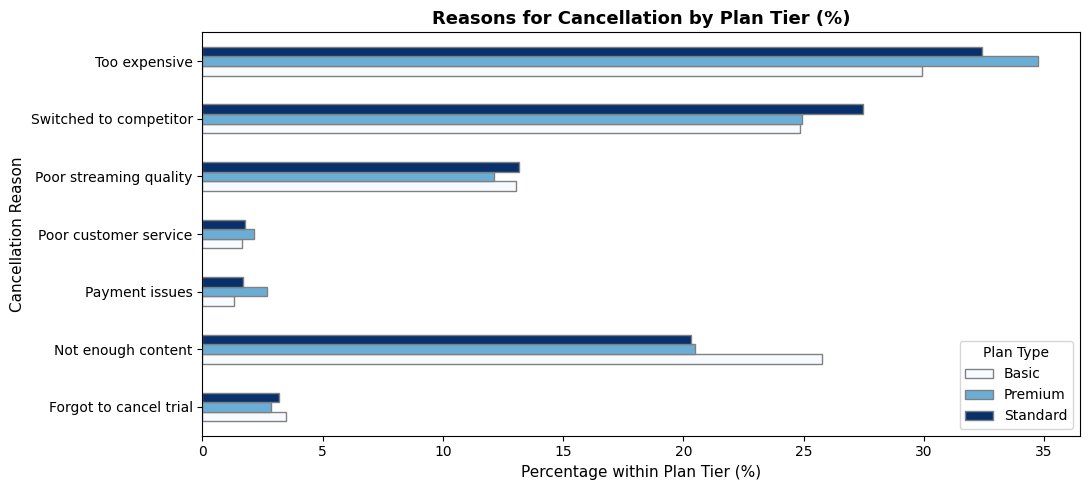

In [98]:
# 4.4 Primary Cancellation Reasons Normalized by Plan Type

churned_customers = df[df['churn_flag'] == 1]

reason_plan_pct = pd.crosstab(
    churned_customers['cancellation_reason'],
    churned_customers['plan_type'],
    normalize='columns'
) * 100

reason_plan_pct.plot(
    kind='barh',
    figsize=(11, 5),
    colormap='Blues',
    edgecolor='gray'
)
plt.title("Reasons for Cancellation by Plan Tier (%)", fontsize=13, fontweight='bold')
plt.xlabel("Percentage within Plan Tier (%)", fontsize=11)
plt.ylabel("Cancellation Reason", fontsize=11)
plt.legend(title='Plan Type')
plt.tight_layout()
plt.show()

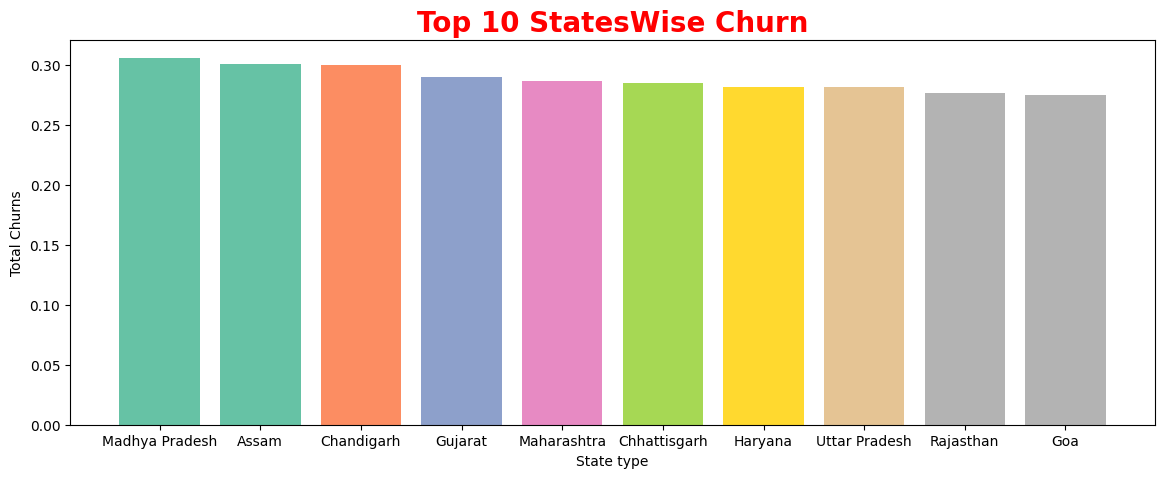

In [58]:
# 4.5 Churn by states

states_trend = df[df['country']=='India'].groupby('state')['churn_flag'].mean().nlargest(10)
colors = plt.cm.Set2(np.linspace(0,1,len(states_trend)))
plt.figure(figsize = (14,5))

plt.bar(states_trend.index, states_trend.values, color  = colors)

plt.title('Top 10 StatesWise Churn',fontsize = 20, color = "red",fontweight='bold')
plt.xlabel('State type')
plt.ylabel("Total Churns")
plt.show()

            churn_rate  customers
churn_risk                       
high          0.635842       1395
low           0.181860       8699
med           0.401889       1906


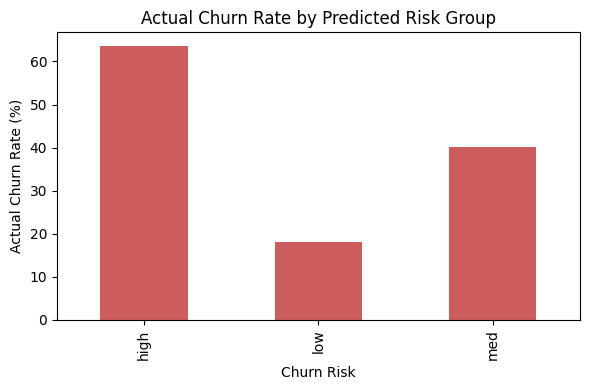

In [96]:
risk_churn = (
    df.groupby('churn_risk', dropna=False)['churn_flag']
      .agg(['mean', 'count'])
      .rename(columns={'mean': 'churn_rate', 'count': 'customers'})
)

print(risk_churn)

risk_churn['churn_rate'].mul(100).plot(
    kind='bar', color='indianred', figsize=(6, 4)
)

plt.title('Actual Churn Rate by Predicted Risk Group')
plt.xlabel('Churn Risk')
plt.ylabel('Actual Churn Rate (%)')
plt.tight_layout()
plt.show()

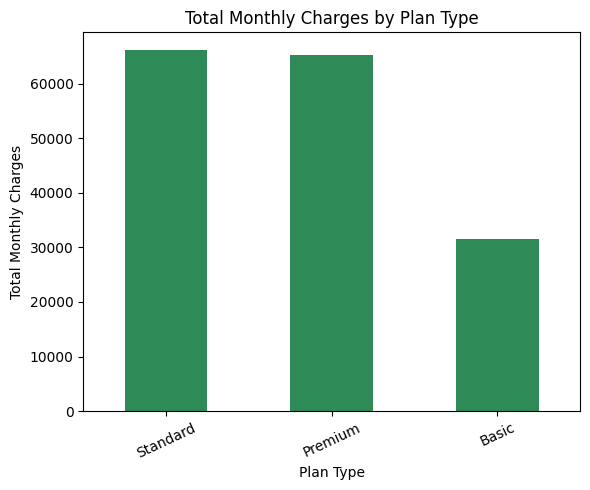

In [94]:
revenue_by_plan = (
    df.groupby('plan_type')['monthly_charges']
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(6, 5))
revenue_by_plan.plot(kind='bar', color='seagreen')

plt.title('Total Monthly Charges by Plan Type')
plt.xlabel('Plan Type')
plt.ylabel('Total Monthly Charges')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

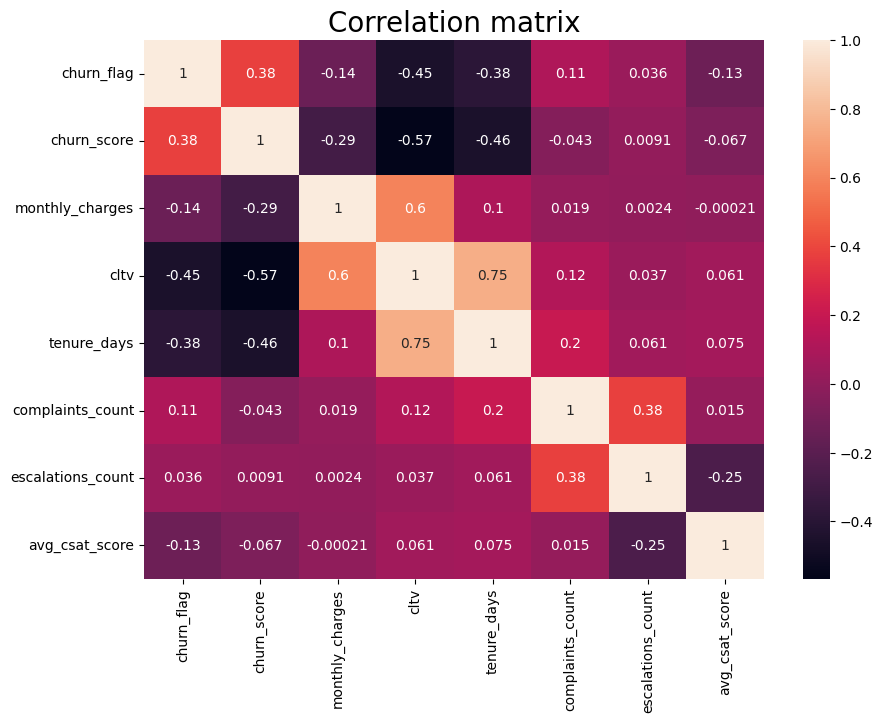

In [49]:
# 4.6 Heatmap  (Correlation matrix)
heatmap_cols = [
    'churn_flag', 'churn_score', 'monthly_charges', 'cltv',
    'tenure_days', 'complaints_count', 'escalations_count', 'avg_csat_score'
]

plt.figure(figsize=(10, 7))

sns.heatmap(df[heatmap_cols].corr(),annot = True)

plt.title("Correlation matrix",fontsize = 20)
plt.show()

In [44]:
# PIVOT TABLE 1: Plan Type vs. Contract Type Churn 

pivot_plan_contract = pd.pivot_table(
    df,
    index='plan_type',
    columns='contract_type',
    values='churn_flag',
    aggfunc=['count', lambda x: round(np.mean(x) * 100, 2)]
)
pivot_plan_contract.columns = ['Subscribers (Annual)', 'Subscribers (Monthly)', 'Churn % (Annual)', 'Churn % (Monthly)']
print("--- Churn Breakdown by Plan and Contract Commitment ---")
display(pivot_plan_contract)



--- Churn Breakdown by Plan and Contract Commitment ---


,Subscribers (Annual),Subscribers (Monthly),Churn % (Annual),Churn % (Monthly)
plan_type,,,,
Basic,1319,2469,20.39,45.04
Premium,2013,1089,12.07,29.20
Standard,2651,2459,14.60,36.84


In [45]:
# PIVOT TABLE 2: Monthly Revenue at Risk by Stated Reason

churned_customers = df[df['churn_flag'] == 1]
pivot_reasons = pd.pivot_table(
    churned_customers,
    index='cancellation_reason',
    columns='plan_type',
    values='monthly_charges',
    aggfunc=['count', 'sum'],
    margins=True,
    margins_name='Total'
)
print("\n--- Lost Monthly Revenue by Cancellation Reason & Plan Tier ---")
display(pivot_reasons.round(2))


--- Lost Monthly Revenue by Cancellation Reason & Plan Tier ---


count                              sum            \
plan_type              Basic Premium Standard Total     Basic   Premium   
cancellation_reason                                                       
Forgot to cancel trial    48      16       41   105    409.52    327.84   
Not enough content       356     115      263   734   2952.44   2440.85   
Payment issues            18      15       22    55    152.82    310.85   
Poor customer service     23      12       23    58    194.77    252.88   
Poor streaming quality   180      68      170   418   1489.20   1385.32   
Switched to competitor   343     140      355   838   2858.57   2931.60   
Too expensive            413     195      419  1027   3466.87   4198.05   
Total                   1381     561     1293  3235  11524.19  11847.39   

                                            
plan_type               Standard     Total  
cancellation_reason                         
Forgot to cancel trial    540.59   1277.95  
Not enough content       3384.37   8777.66  
Payment issues            283.78    747.45  
Poor customer service     302.77    750.42  
Poor streaming quality   2199.30   5073.82  
Switched to competitor   4621.45  10411.62  
Too expensive            5468.81  13133.73  
Total                   16801.07  40172.65

---
## 🎯 Conclusion & Strategic Recommendations

### 1. Executive Summary of Key Findings
* **Retention Landscape:** The platform experiences an overall **churn rate of 26.96%**, representing **₹40,172 in monthly recurring revenue (MRR) at risk**.
* **Plan Tier Sensitivity:** The **Basic plan** exhibits the highest churn rate at **36.46%**, compared to **18.09% for Premium users**, indicating perceived value gaps or price sensitivity at the lower tier.
* **Customer Support Impact:** Ticket escalations have a **positive correlation (+0.26) with churn**, demonstrating that unresolved customer grievances are a leading trigger for subscription cancellations.

### 2. Actionable Business Recommendations
1. **Prioritize Escalation Resolution (Fast-Track SLA):** Customers who experience support ticket escalations should be flagged in the CRM and assigned to specialized retention specialists within 2 hours.
2. **Revamp Basic Tier Onboarding:** Because Basic tier users churn at twice the rate of Premium subscribers, introduce targeted feature walkthroughs and engagement nudges during the first 30 days of subscription.
3. **Automated At-Risk Retention Triggers:** Accounts scoring in the **High Churn Risk tier (Churn Score ≥ 70)** should automatically trigger personalized renewal incentives or proactive check-ins.

### 3. Future Scope
* Train a machine learning classification model (Random Forest / XGBoost) to predict individual churn probabilities.
* Perform RFM (Recency, Frequency, Monetary) segmentation to personalize customer lifetime value optimization strategies.


### 👤 Author & Connect
* **Analyst:** Apoorava Modi
* **LinkedIn:** [www.linkedin.com/in/apoorvmodi](https://www.linkedin.com/in/apoorvmodi)
* **GitHub:** [https://github.com/apoorvmodi?tab=repositories](https://github.com/apoorvmodi?tab=repositories)
---